In [2]:
import pandas as pd
import numpy as np
import time

In [46]:
# Read csv files
pnrs = pd.read_csv('PRMI_DM_ALL_PNRs.csv')
targets = pd.read_csv('PRMI-DM_TARGET_FLIGHTS.csv')
flights = pd.read_csv('PRMI-DM-AVAILABLE_FLIGHTS.csv')

# Quick edits to data
# Aggregate seat counts
targets['AVAIL_CNT'] = targets['C_AVAIL_CNT'] + targets['Y_AVAIL_CNT']
flights['AVAIL_CNT'] = flights['C_AVAIL_CNT'] + flights['Y_AVAIL_CNT']
# Drop unnecessary columns
pnrs = pnrs.drop(columns=['CREATION_DTZ', 'CABIN_CD', 'COS_CD', 'OPER_OD_ORIG_CD', 'DEP_DT', 'FLT_NUM', 'DEP_DTML', 'ARR_DTML'])
targets = targets.drop(columns=['CHANGE_TYPE', 'DEP_DT', 'DEP_DTML', 'ARR_DTML', 'C_CAP_CNT', 'C_AUL_CNT', 'C_PAX_CNT', 'Y_CAP_CNT', 'Y_AUL_CNT', 'Y_PAX_CNT', 'C_AVAIL_CNT', 'Y_AVAIL_CNT'])
flights = flights.drop(columns=['DEP_DT', 'DEP_DTML', 'ARR_DTML', 'C_CAP_CNT', 'C_AUL_CNT', 'C_PAX_CNT', 'Y_CAP_CNT', 'Y_AUL_CNT', 'Y_PAX_CNT', 'C_AVAIL_CNT', 'Y_AVAIL_CNT'])
# Convert DTMZ columns to datetime
pnrs['DEP_DTMZ'] = pd.to_datetime(pnrs['DEP_DTMZ'], format='%Y-%m-%d %H:%M:%S')
pnrs['ARR_DTMZ'] = pd.to_datetime(pnrs['ARR_DTMZ'], format='%Y-%m-%d %H:%M:%S')
targets['DEP_DTMZ'] = pd.to_datetime(targets['DEP_DTMZ'], format='%Y-%m-%d %H:%M:%S')
targets['ARR_DTMZ'] = pd.to_datetime(targets['ARR_DTMZ'], format='%Y-%m-%d %H:%M:%S')
flights['DEP_DTMZ'] = pd.to_datetime(flights['DEP_DTMZ'], format='%Y-%m-%d %H:%M:%S')
flights['ARR_DTMZ'] = pd.to_datetime(flights['ARR_DTMZ'], format='%Y-%m-%d %H:%M:%S')

# Check validity
pnrs.info()
targets.info()
flights.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43832 entries, 0 to 43831
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   RECLOC           43832 non-null  int64         
 1   OPER_OD_DEST_CD  43832 non-null  object        
 2   DEP_KEY          43832 non-null  object        
 3   ORIG_CD          43832 non-null  object        
 4   DEST_CD          43832 non-null  object        
 5   DEP_DTMZ         43832 non-null  datetime64[ns]
 6   ARR_DTMZ         43832 non-null  datetime64[ns]
 7   OD_BROKEN_IND    43832 non-null  int64         
 8   PAX_CNT          43832 non-null  int64         
 9   CVM              43832 non-null  float64       
 10  CONN_TIME_MINS   18059 non-null  float64       
dtypes: datetime64[ns](2), float64(2), int64(3), object(4)
memory usage: 3.7+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 168 entries, 0 to 167
Data columns (total 7 columns):
 #   Column     N

In [47]:
max_delay = 72

flights_updated = []
def create_route(orig, dest, start_time, path):
    '''
    Generates possible routes by recursively searching flights dataset until end destination is reached
    Fails if no route is found in under 48 hours from start_time
    Returns a list of all found routes
    '''
    routes = []
    test_path = path.copy() # Copy the path
    path_cities = []
    # Find earliest departure time for flights
    if len(test_path) > 0:
        last_flight_time = flights[flights['DEP_KEY'] == test_path[-1]].iloc[0]['ARR_DTMZ']
    else:
        last_flight_time = pd.Timestamp(year=2000, month=1, day=1)

    for flight in test_path:
        path_cities.append(flights[flights['DEP_KEY'] == flight].iloc[0]['ORIG_CD'])

    
    filtered_flights = flights[flights['ORIG_CD'] == orig] # Filter wrong origin codes
    filtered_flights = filtered_flights[~filtered_flights['DEST_CD'].isin(path_cities)] # Filter flights that go to a previously visited city
    # filtered_flights = filtered_flights[filtered_flights['DEP_DTMZ'] > last_flight_time] # Filter too early flights

    # Filter too early or late flights
    indices_to_drop = []
    for idx, flight in filtered_flights.iterrows():
        if last_flight_time.year == 2000:
            connection_hours = 1
        else:
            connection_hours = (flight['DEP_DTMZ'] - last_flight_time).value / 3.6e12 # Convert connection miliseconds to hours
        delay_hours = (flight['ARR_DTMZ'] - start_time).value / 3.6e12 # Convert total reroute miliseconds to hours
        if flight['DEP_DTMZ'] < start_time or delay_hours > max_delay or connection_hours < 1:
            indices_to_drop.append(idx)
    filtered_flights = filtered_flights.drop(indices_to_drop)

    # Find new flights
    test_path.append('') # Add element to replace with test cities
    for idx, flight in filtered_flights.iterrows():
        test_path[-1] = flight['DEP_KEY'] # Insert flight into path being tested
        if flight['DEST_CD'] == dest: # Destination found
            # Get times
            dep_time_first = flights.loc[
                flights['DEP_KEY'] == test_path[0], 'DEP_DTMZ'
            ].iloc[0]
            arr_time_last = flights.loc[
                flights['DEP_KEY'] == test_path[-1], 'ARR_DTMZ'
            ].iloc[0]
            
            # Append times to route
            completed_route = {
                "Flight_path": test_path.copy(),
                "Origin": orig,
                "Destination": dest,
                "Departure_time": dep_time_first,
                "Arrival_time": arr_time_last
            }
            
            routes.append(completed_route.copy())
            continue
        # Recursive search
        subroutes = create_route(flight['DEST_CD'], dest, start_time, test_path)
        if len(subroutes) > 0:
            for row in subroutes:
                routes.append(row)

    return routes

In [48]:
# Start runtime
start_time = time.perf_counter()

# Calculate alternate routes
alt_routes = []

# Remove cancelled flights from the dataset
for key in targets['DEP_KEY']:
    flights = flights[flights['DEP_KEY'] != key]

# Iterate through cancelled flights
# Find new routes leading to destination city
# Skip route as soon as it takes >48H
# Store routes in a list
for idx, irop in targets.iterrows():
    routes = create_route(irop['ORIG_CD'], irop['DEST_CD'], irop['DEP_DTMZ'], [])
    for row in routes:
        alt_routes.append(row)


# Check runtime
end_time = time.perf_counter()

elapsed_time = end_time - start_time
print(f"Execution time: {elapsed_time:.4f} seconds")

Execution time: 257.4449 seconds


In [49]:
# Remove duplicate routes
# print(alt_routes)
# alt_routes = [list(row) for row in set(tuple(row) for row in alt_routes)]
print(alt_routes)

[{'Flight_path': ['AZ20271023TPHNWY10061'], 'Origin': 'TPH', 'Destination': 'NWY', 'Departure_time': Timestamp('2027-10-23 23:19:00'), 'Arrival_time': Timestamp('2027-10-24 02:56:00')}, {'Flight_path': ['AZ20271022TPHNWY10061'], 'Origin': 'TPH', 'Destination': 'NWY', 'Departure_time': Timestamp('2027-10-22 23:19:00'), 'Arrival_time': Timestamp('2027-10-23 02:56:00')}, {'Flight_path': ['AZ20271021TPHNWY19873'], 'Origin': 'TPH', 'Destination': 'NWY', 'Departure_time': Timestamp('2027-10-22 08:57:00'), 'Arrival_time': Timestamp('2027-10-22 12:34:00')}, {'Flight_path': ['AZ20271023TPHNWY19873'], 'Origin': 'TPH', 'Destination': 'NWY', 'Departure_time': Timestamp('2027-10-24 08:57:00'), 'Arrival_time': Timestamp('2027-10-24 12:34:00')}, {'Flight_path': ['AZ20271022TPHNWY19873'], 'Origin': 'TPH', 'Destination': 'NWY', 'Departure_time': Timestamp('2027-10-23 08:57:00'), 'Arrival_time': Timestamp('2027-10-23 12:34:00')}, {'Flight_path': ['AZ20271021TPHNWY4086'], 'Origin': 'TPH', 'Destination': 

In [50]:
# import json

# file_path = "alternate_flight_paths.json"

# with open(file_path, "w") as file:
#     json.dump(alt_routes, file, indent=4)

In [51]:
# Find passengers with missed flights, including some flight details
filtered_pnrs = pnrs[pnrs["DEP_KEY"].isin(targets["DEP_KEY"])]
affected_pnrs = filtered_pnrs[["RECLOC", "ORIG_CD", "DEST_CD", "PAX_CNT", "CVM", "DEP_DTMZ", "ARR_DTMZ"]]
print(affected_pnrs)

       RECLOC ORIG_CD DEST_CD  PAX_CNT       CVM            DEP_DTMZ  \
0           0     EBG     TPH        1  3.321928 2027-10-22 19:06:00   
2           1     TPH     RHP        3  5.689050 2027-10-21 23:25:00   
6           2     TPH     OLT        1  5.855710 2027-10-21 23:07:00   
10          3     TPH     FHY        3  5.184875 2027-10-21 20:34:00   
15          4     TPH     GIW        3  2.459678 2027-10-22 09:42:00   
...       ...     ...     ...      ...       ...                 ...   
43815   14182     TPH     EYF        1  3.629400 2027-10-21 08:46:00   
43818   14183     EYF     TPH        2  4.070539 2027-10-22 02:17:00   
43820   14184     GCH     TPH        1  4.142910 2027-10-21 13:58:00   
43826   14185     PTP     TPH        1  5.603888 2027-10-22 11:06:00   
43828   14186     ALN     TPH        2  3.760025 2027-10-22 22:03:00   

                 ARR_DTMZ  
0     2027-10-22 21:35:00  
2     2027-10-22 02:55:00  
6     2027-10-22 06:19:00  
10    2027-10-21 22:30:

In [52]:
# Check for reused flights
used_flights = []
reused_flights = []
for route in alt_routes:
    for flight in route["Flight_path"]:
        if flight in used_flights:
            if not flight in reused_flights:
                reused_flights.append(flight)
        else:
            used_flights.append(flight)

print(reused_flights)

['AZ20271022VUYQXG10006', 'AZ20271021TPHVUY19976', 'AZ20271021VUYRBR2154', 'AZ20271021RBRQXG5591', 'AZ20271021TPHVUY2154', 'AZ20271023RBRQXG5591', 'AZ20271021VUYQXG10006', 'AZ20271021TPHVUY13778', 'AZ20271020TPHRBR14039', 'AZ20271021RBRVUY4376', 'AZ20271020TPHVUY10006', 'AZ20271021TPHVUY109', 'AZ20271021TPHVUY18979', 'AZ20271020TPHVUY11871', 'AZ20271021TPHVUY14711', 'AZ20271022TPHQXG9080', 'AZ20271021TPHQXG9080', 'AZ20271023QXGVUY8894', 'AZ20271022TPHVUY17637', 'AZ20271022TPHQXG14385', 'AZ20271022TPHVUY19976', 'AZ20271022TPHVUY2154', 'AZ20271022TPHQXG7185', 'AZ20271021TPHQXG7185', 'AZ20271022QXGVUY8894', 'AZ20271022TPHQXG5430', 'AZ20271022TPHVUY13778', 'AZ20271021TPHVUY10006', 'AZ20271022TPHVUY109', 'AZ20271022TPHVUY18979', 'AZ20271022TPHVUY14711', 'AZ20271023VUYQXG10006', 'AZ20271024RBRTPH7756', 'AZ20271023QXGRBR14385', 'AZ20271024QXGTPH2732', 'AZ20271024QXGTPH2972', 'AZ20271024QXGTPH15389', 'AZ20271024QXGTPH5591', 'AZ20271023VUYTPH5659', 'AZ20271024VUYTPH5659', 'AZ20271023VUYTPH18329

In [53]:
# Convert the list of dictionaries to a dataframe
routes_df = pd.DataFrame(alt_routes)
# Sort routes by arrival time for better convenience
routes_df.sort_values(by="Arrival_time")
print(routes_df)

                  Flight_path Origin Destination      Departure_time  \
0     [AZ20271023TPHNWY10061]    TPH         NWY 2027-10-23 23:19:00   
1     [AZ20271022TPHNWY10061]    TPH         NWY 2027-10-22 23:19:00   
2     [AZ20271021TPHNWY19873]    TPH         NWY 2027-10-22 08:57:00   
3     [AZ20271023TPHNWY19873]    TPH         NWY 2027-10-24 08:57:00   
4     [AZ20271022TPHNWY19873]    TPH         NWY 2027-10-23 08:57:00   
...                       ...    ...         ...                 ...   
2488   [AZ20271020TPHNWY7746]    TPH         NWY 2027-10-21 08:55:00   
2489  [AZ20271022TPHNWY16107]    TPH         NWY 2027-10-22 20:24:00   
2490  [AZ20271021TPHNWY16107]    TPH         NWY 2027-10-21 20:24:00   
2491  [AZ20271023TPHNMK13145]    TPH         NMK 2027-10-23 18:43:00   
2492  [AZ20271022TPHNMK13145]    TPH         NMK 2027-10-22 18:43:00   

            Arrival_time  
0    2027-10-24 02:56:00  
1    2027-10-23 02:56:00  
2    2027-10-22 12:34:00  
3    2027-10-24 12:34:00  


In [54]:
# Start runtime
start_time = time.perf_counter()

# Iterate through displaced passengers based on cvm score and place them on good flights
affected_pnrs = affected_pnrs.sort_values(by="CVM", ascending=False)
affected_pnrs["Assigned"] = False

affected_pnrs_copy = affected_pnrs.copy()
for idx, pnr in affected_pnrs_copy.iterrows():
    # Same destination and origin and displaced flight
    potential_routes = routes_df[routes_df["Origin"] == pnr["ORIG_CD"]]
    potential_routes = potential_routes[potential_routes["Destination"] == pnr["DEST_CD"]]
    # Departs at least 1 hour later than the displaced flight would have
    potential_routes = potential_routes[potential_routes["Departure_time"] > pnr["DEP_DTMZ"] + pd.Timedelta(hours=1)]
    # Arrives at most max_delay hours later than the displaced flight would have
    potential_routes = potential_routes[potential_routes["Departure_time"] < pnr["ARR_DTMZ"] + pd.Timedelta(hours=max_delay)]
    # Order of potential_routes should have remained the same, with the fastest arrival times first
    # Now assign the pnr to the first available flight with enough seats for PAX_CNT on all flights
    for idx2, route in potential_routes.iterrows():
        good_path = True
        # Check flight path for enough seats
        for flight in route["Flight_path"]: # Triple for-loop of doom
            # Find flight details
            seat_count = flights.loc[
                flights["DEP_KEY"] == flight, "AVAIL_CNT"
            ].iloc[0]
            # Check seat count
            if seat_count < pnr["PAX_CNT"]:
                good_path = False
                break

        # Check if path was good
        if good_path:
            # Decrease available seats for all flights in route
            for flight in route["Flight_path"]:
                seats = flights.loc[flights["DEP_KEY"] == flight, "AVAIL_CNT"]
                flights.loc[flights["DEP_KEY"] == flight, "AVAIL_CNT"] = seats - pnr["PAX_CNT"]
            affected_pnrs_copy.loc[idx, "Assigned"] = True
            break


# Check runtime
end_time = time.perf_counter()

elapsed_time = end_time - start_time
print(f"Execution time: {elapsed_time:.4f} seconds")
print(affected_pnrs_copy)

Execution time: 403.4294 seconds
       RECLOC ORIG_CD DEST_CD  PAX_CNT        CVM            DEP_DTMZ  \
3851     1269     RZD     TPH        1  12.712612 2027-10-21 15:49:00   
14528    4754     BPJ     TPH        1  12.115262 2027-10-21 20:26:00   
19707    6443     PTP     TPH        1  12.005011 2027-10-22 11:06:00   
22307    7262     TPH     ERW        4  11.404789 2027-10-20 18:47:00   
39152   12669     TPH     EYF        1  11.332327 2027-10-21 05:44:00   
...       ...     ...     ...      ...        ...                 ...   
42020   13608     OSW     TPH        1   0.000000 2027-10-22 16:30:00   
11682    3817     TPH     RHP        1   0.000000 2027-10-21 05:42:00   
11324    3694     QXG     TPH        1   0.000000 2027-10-21 17:03:00   
29852    9682     OSW     TPH        4   0.000000 2027-10-22 16:30:00   
29688    9627     RHP     TPH        4   0.000000 2027-10-22 04:12:00   

                 ARR_DTMZ  Assigned  
3851  2027-10-21 21:54:00      True  
14528 2027-10-

In [55]:
counts = affected_pnrs_copy["Assigned"].value_counts()
rate = counts[True] / (counts[True]+counts[False])
print("Value counts of assigned passengers")
print(counts)
print("------------------------------------")

assigned_pnrs = affected_pnrs_copy[affected_pnrs_copy["Assigned"] == True]
assigned_people = assigned_pnrs["PAX_CNT"].sum()
total_people = affected_pnrs_copy["PAX_CNT"].sum()

print(f"Reaccomodation rate: {assigned_people / total_people}")

Value counts of assigned passengers
Assigned
True     8365
False    6731
Name: count, dtype: int64
------------------------------------
Reaccomodation rate: 0.5529755690123199


In [56]:
# Store data from multiple runs
delay_times = [24, 48, 72] # hours
reroute_times = [71.2148, 151.7629, 257.4449] # seconds
reassign_times = [126.0198, 286.9289, 403.4294] # seconds
success_rates = [0.09150135727709334, 0.40338275214032154, 0.5529755690123199]

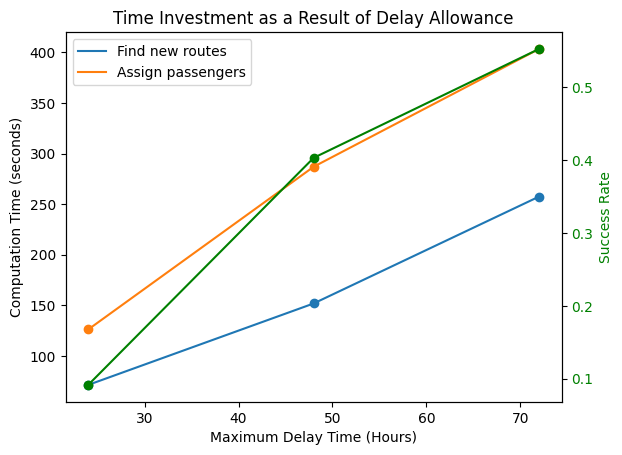

In [57]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots()
ax1.plot(delay_times, reroute_times, label="Find new routes")
ax1.scatter(delay_times, reroute_times)
ax1.plot(delay_times, reassign_times, label="Assign passengers")
ax1.scatter(delay_times, reassign_times)
ax1.set_title("Time Investment as a Result of Delay Allowance")
ax1.set_xlabel("Maximum Delay Time (Hours)")
ax1.set_ylabel("Computation Time (seconds)")

ax2 = ax1.twinx()
ax2.plot(delay_times, success_rates, label="Reassign Rates", color="green")
ax2.scatter(delay_times, success_rates, color="green")
ax2.set_ylabel("Success Rate", color="green")
ax2.tick_params(axis='y', labelcolor="green")

ax1.legend()
plt.show()

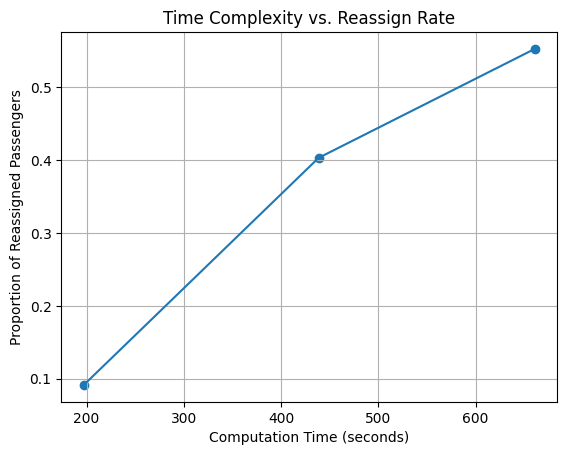

In [58]:
total_compute_times = []
for i in range(len(reroute_times)):
    total_compute_times.append(reassign_times[i] + reroute_times[i])

plt.plot(total_compute_times, success_rates)
plt.scatter(total_compute_times, success_rates)
plt.title("Time Complexity vs. Reassign Rate")
plt.xlabel("Computation Time (seconds)")
plt.ylabel("Proportion of Reassigned Passengers")
plt.grid()
plt.show()